# Funnel Plot (institutional comparison)

**Family:** Scientific &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Scientific:* Specialised plots for statistics and scientific research: survival, effect sizes, agreement, omics, study flow and longitudinal data.

## Design purpose

Plots each unit's performance (a rate, a return, an alpha) against its size or exposure (volume, track record), with control limits that narrow as size grows. Small units naturally swing further by chance, so the limits form a funnel. Only units outside the funnel differ by more than chance alone would produce.

## When to use

- Compare many funds, branches, traders or suppliers whose results rest on very different amounts of data
- Replace a league table, which rewards small units for lucky extremes
- Decide which units deserve investigation (outside the 99.8% limits) and which are noise

## Avoid when

- All units have the same size (control limits are flat; a dot plot with one band does the job)
- The performance measure isn't comparable across units (adjust for risk or case mix first)
- Units are not independent, or there is real overdispersion you haven't modelled (widen the limits first)

## Alternatives

- Caterpillar plot (ranked estimates with CIs)
- Forest plot
- Shrinkage (empirical Bayes) estimates in a ranked dot plot

## Design tips

- What it fixes: ranking tables put the luckiest small units at the top and bottom; the funnel shows that most of those extremes are noise
- Use 95% (≈2 SD) limits as a warning and 99.8% (≈3 SD) limits as an alarm
- Label only the units outside the outer limits; everything inside is consistent with the benchmark
- If many units fall outside, the limits are too narrow (overdispersion); inflate them before drawing conclusions

## Example

150 simulated equity funds. Annualised alpha vs. the benchmark is plotted against track-record length, with tracking error of 5% a year. Almost all funds have no true skill; three long-running funds genuinely add or destroy value.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(2005)
n = 150
te = 0.05  # annual tracking error: alpha's year-to-year noise
years = np.round(rng.gamma(2.2, 3.0, n).clip(1, 25), 1)
order = np.argsort(-years)
true_alpha = np.zeros(n)
true_alpha[order[[0, 2]]] = 0.045   # two genuinely skilled, long-running funds
true_alpha[order[4]] = -0.045       # one that consistently destroys value
alpha = true_alpha + rng.normal(0, te / np.sqrt(years))
df = pd.DataFrame({"fund": [f"Fund {i:03d}" for i in range(1, n + 1)], "years": years, "alpha": alpha})
se = te / np.sqrt(df["years"])
df["z"] = df["alpha"] / se
df.sort_values("z").iloc[[0, 1, -2, -1]].round(3)

,fund,years,alpha,z
5,Fund 006,18.3,-0.049,-4.162
133,Fund 134,1.4,-0.099,-2.342
21,Fund 022,20.7,0.038,3.422
77,Fund 078,25.0,0.044,4.426


### Plot

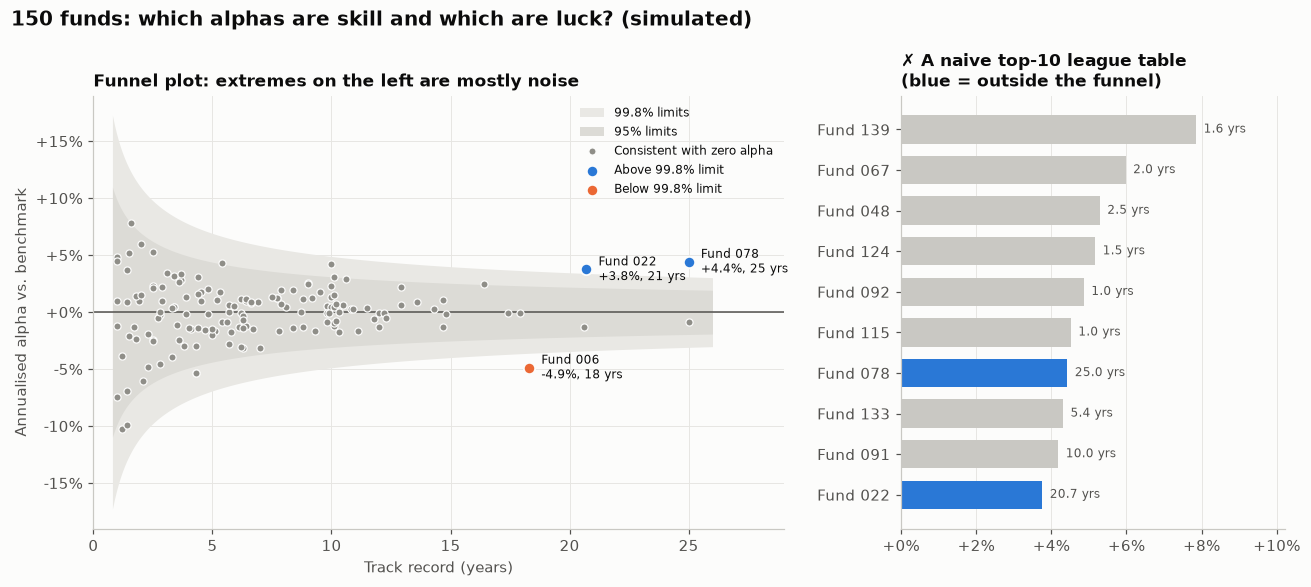

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={"width_ratios": [1.8, 1]})
t = np.linspace(0.8, df["years"].max() + 1, 300)
for z, shade, label in ((3.09, "#e9e8e4", "99.8% limits"), (1.96, "#dcdbd6", "95% limits")):
    a1.fill_between(t, -z * te / np.sqrt(t), z * te / np.sqrt(t), color=shade, linewidth=0, label=label)
a1.axhline(0, color="#52514e", linewidth=1)
out_hi, out_lo = df["z"] > 3.09, df["z"] < -3.09
inside = ~(out_hi | out_lo)
a1.scatter(df.loc[inside, "years"], df.loc[inside, "alpha"], s=22, color="#8f8e88", edgecolor="#fcfcfb",
           linewidth=0.8, label="Consistent with zero alpha", zorder=3)
a1.scatter(df.loc[out_hi, "years"], df.loc[out_hi, "alpha"], s=55, color=PALETTE[0], edgecolor="#fcfcfb",
           linewidth=1.2, label="Above 99.8% limit", zorder=4)
a1.scatter(df.loc[out_lo, "years"], df.loc[out_lo, "alpha"], s=55, color=PALETTE[1], edgecolor="#fcfcfb",
           linewidth=1.2, label="Below 99.8% limit", zorder=4)
for r in df[~inside].itertuples():
    a1.annotate(f"{r.fund}\n{r.alpha:+.1%}, {r.years:.0f} yrs", (r.years, r.alpha), xytext=(8, 0),
                textcoords="offset points", fontsize=8, va="center")
a1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
a1.set_xlabel("Track record (years)")
a1.set_ylabel("Annualised alpha vs. benchmark")
a1.set_title("Funnel plot: extremes on the left are mostly noise", fontsize=11)
a1.legend(loc="upper right", fontsize=8)
a1.set_xlim(0, df["years"].max() + 4)

top = df.nlargest(10, "alpha").iloc[::-1]
colors = np.where(top["z"] > 3.09, PALETTE[0], "#c9c8c3")
a2.barh(top["fund"], top["alpha"], color=colors, height=0.7)
for y, r in enumerate(top.itertuples()):
    a2.text(r.alpha + 0.002, y, f"{r.years:.1f} yrs", va="center", fontsize=8, color="#52514e")
a2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
a2.set_xlim(0, top["alpha"].max() * 1.3)
a2.set_title("✗ A naive top-10 league table\n(blue = outside the funnel)", fontsize=11)
a2.grid(axis="y", visible=False)

fig.suptitle("150 funds: which alphas are skill and which are luck? (simulated)", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
plt.show()

## How to read it

The dots near the left edge, with short track records, show the most extreme alphas. They sit inside the funnel because a year or two of results says little. Only the labelled funds, all with long track records, fall outside the 99.8% limits. The right panel shows how a naive top-10 table would have chosen mostly short-record funds.

## Reference

This method comes from the research literature:

- Spiegelhalter, D. J. (2005). Funnel plots for comparing institutional performance. Statistics in Medicine 24(8), 1185–1202. <https://doi.org/10.1002/sim.1970>

---
Standalone script: [`funnel_plot.py`](funnel_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)